In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

print("Path to dataset files:", path)

c:\Users\laaou\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\laaou\.cache\kagglehub\datasets\maqdadali\mental-health-risk-prediction-dataset-students\versions\1


In [2]:
import pandas as pd
import os

# Build the correct path to the CSV file
file_path = os.path.join(path, "student_mental_health.csv")

# Load the CSV into a DataFrame
df = pd.read_csv(file_path)

# Display the first 5 rows
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [3]:
print(df.shape)
print(df.ndim)

(2000, 17)
2


In [4]:
print(df.isna().sum())
print(df[df.duplicated(keep=False)])



Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
Empty DataFrame
Columns: [Student_ID, Age, Gender, Year_of_Study, Sleep_Hours, Study_Hours_Per_Week, GPA, Social_Media_Hours, Screen_Time_Hours, Physical_Activity, Financial_Stress, Family_Support, Attendance_Rate, Part_Time_Job, Diet_Quality, Previous_Mental_Health_History, Mental_Health_Risk]
Index: []


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [6]:
# Get numerical columns only
numerical_cols = df.select_dtypes(include="number").columns

print(numerical_cols)

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')


In [7]:
# Calculate Q1, Q3 and IQR
Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    ((df[numerical_cols] < lower_bound) |
     (df[numerical_cols] > upper_bound)).any(axis=1)
]

print("Number of outlier rows:", len(outliers))
outliers.head()

Number of outlier rows: 57


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
22,STU0023,21,Male,3,7.0,22.3,2.63,2.4,5.2,Moderate,6.9,7.2,82.7,No,Average,Yes,Medium
36,STU0037,21,Female,3,4.8,24.0,2.25,5.3,6.6,Low,7.7,7.1,61.1,No,Poor,No,High
180,STU0181,22,Male,4,6.4,24.1,2.68,9.0,10.6,Moderate,6.2,6.0,89.8,No,Average,No,High
209,STU0210,29,Female,4,6.5,22.1,3.02,7.5,7.3,Moderate,7.8,6.9,90.4,Yes,NaN,No,Low
217,STU0218,20,Non-binary,5,7.6,34.9,2.77,2.8,5.8,Moderate,8.1,5.2,86.6,No,Good,No,Low


In [8]:
outlier_counts = (
    (df[numerical_cols] < lower_bound) |
    (df[numerical_cols] > upper_bound)
).sum()

print(outlier_counts)

Age                      4
Year_of_Study            0
Sleep_Hours              2
Study_Hours_Per_Week     7
GPA                      9
Social_Media_Hours      20
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         12
dtype: int64


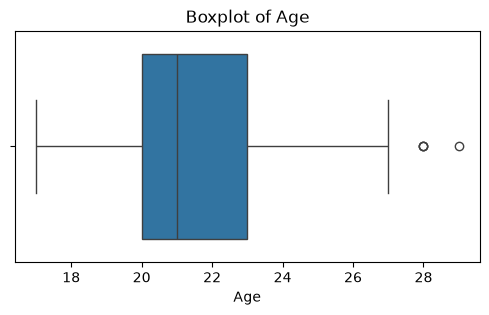

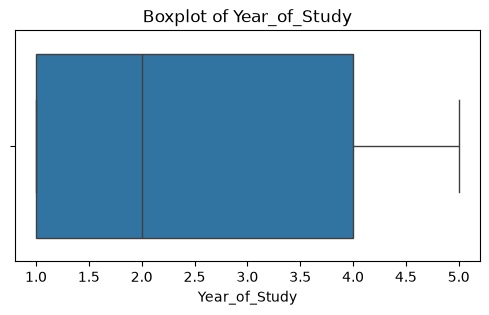

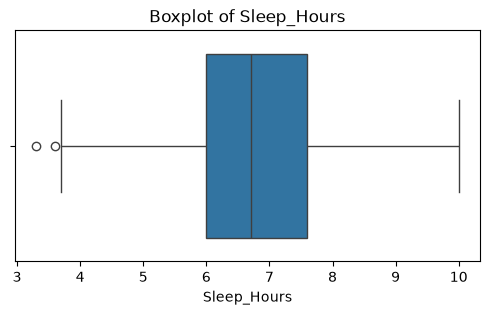

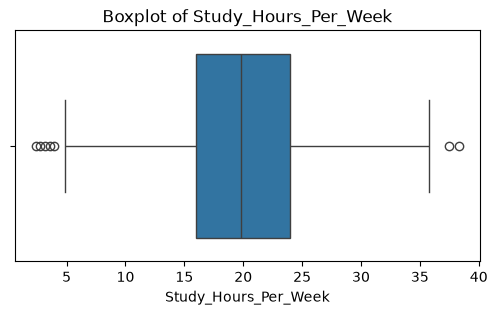

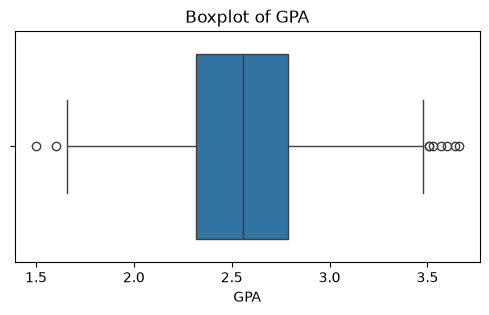

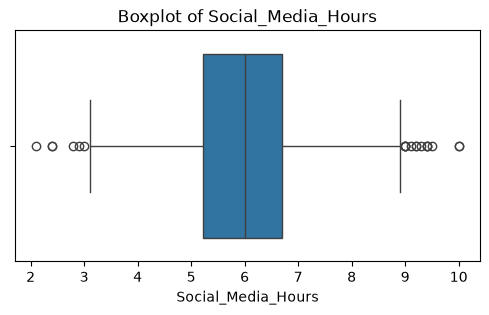

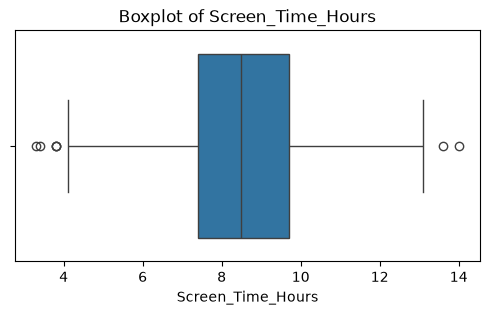

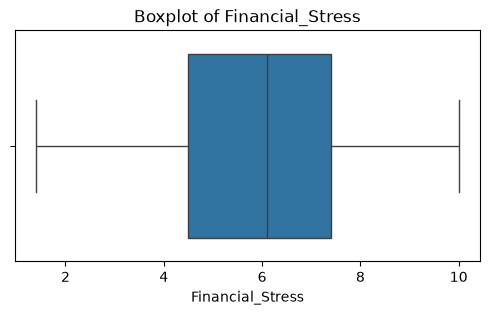

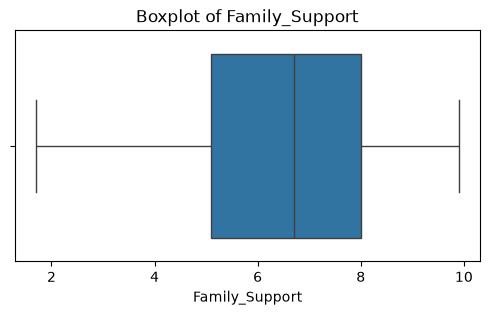

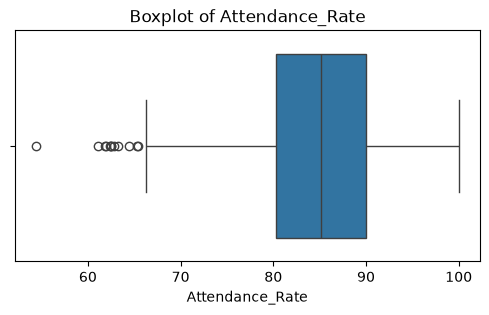

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numerical_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [10]:
df.describe()


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [11]:


# Count the number of observations in each class
class_counts = df["Mental_Health_Risk"].value_counts()

print(class_counts)

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [12]:
# Calculate class distribution in percentage
class_percentage = df["Mental_Health_Risk"].value_counts(normalize=True) * 100

print(class_percentage)

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


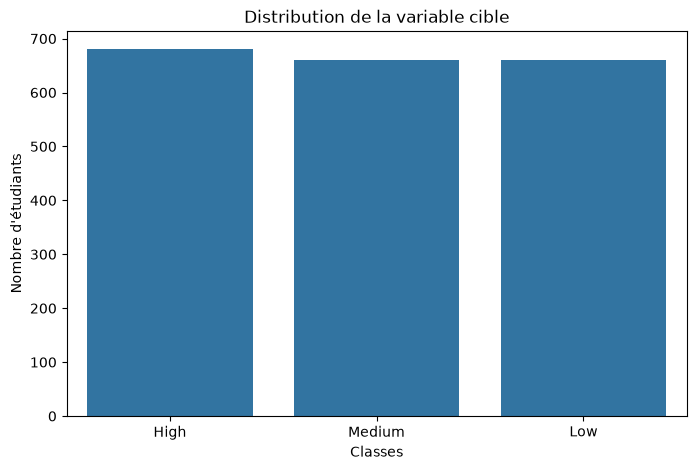

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Mental_Health_Risk")

plt.title("Distribution de la variable cible")
plt.xlabel("Classes")
plt.ylabel("Nombre d'étudiants")

plt.show()

In [14]:


# Separate numerical and categorical features
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

# Remove the target from categorical features
if "Mental_Health_Risk" in categorical_cols:
    categorical_cols.remove("Mental_Health_Risk")

print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)

Numerical features: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical features: ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\laaou\AppData\Local\Temp\ipykernel_13004\1088246778.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


# Relations entre variables catégorielles et cible

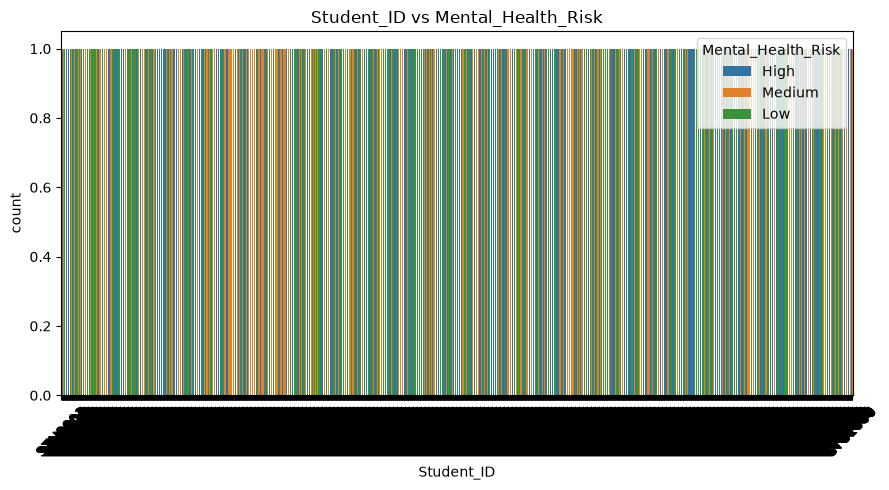

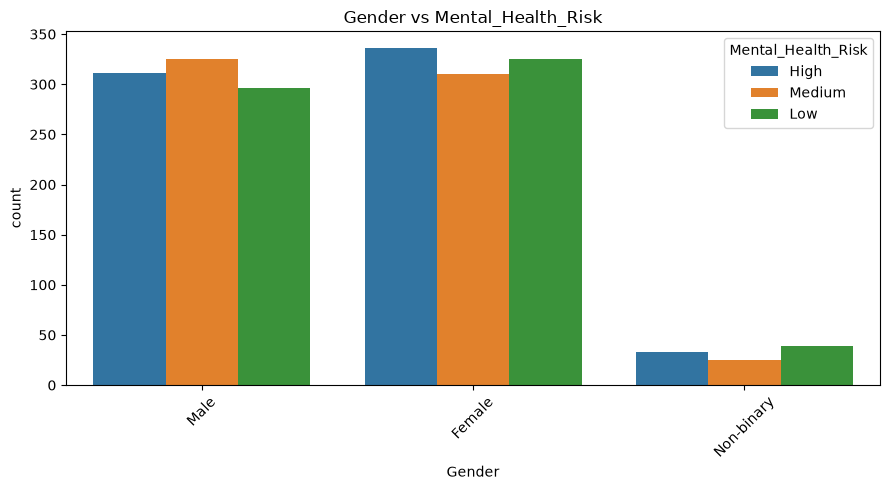

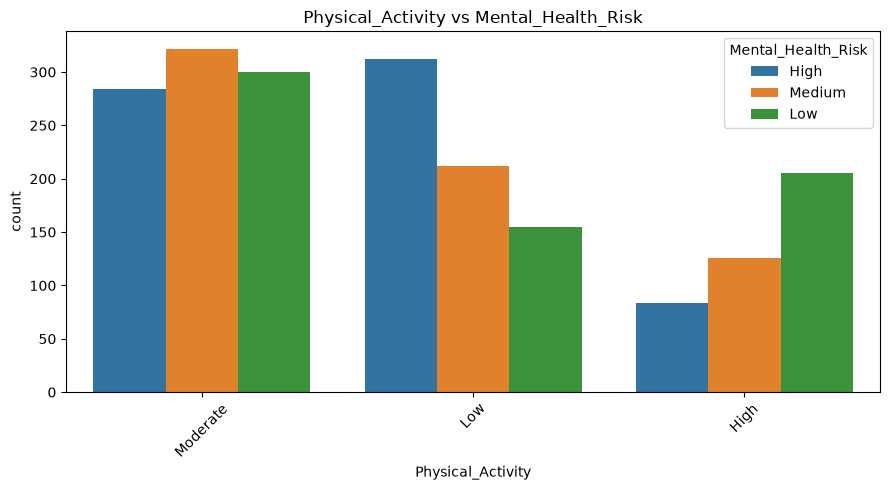

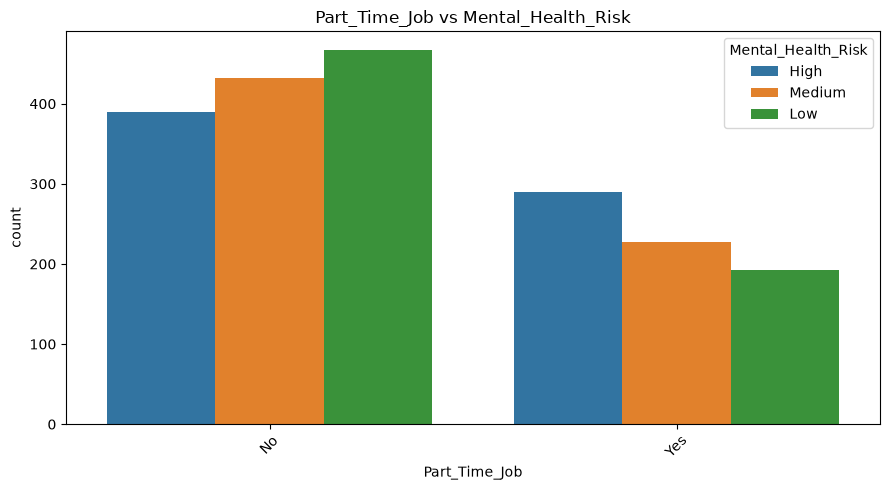

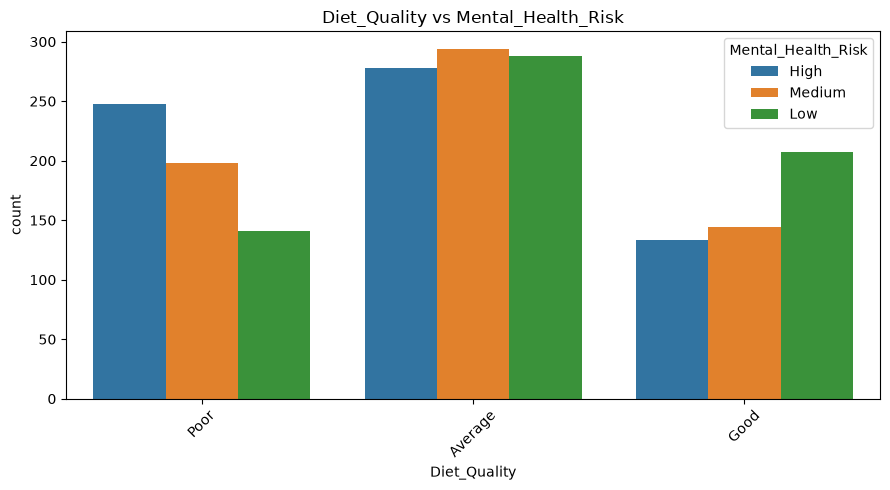

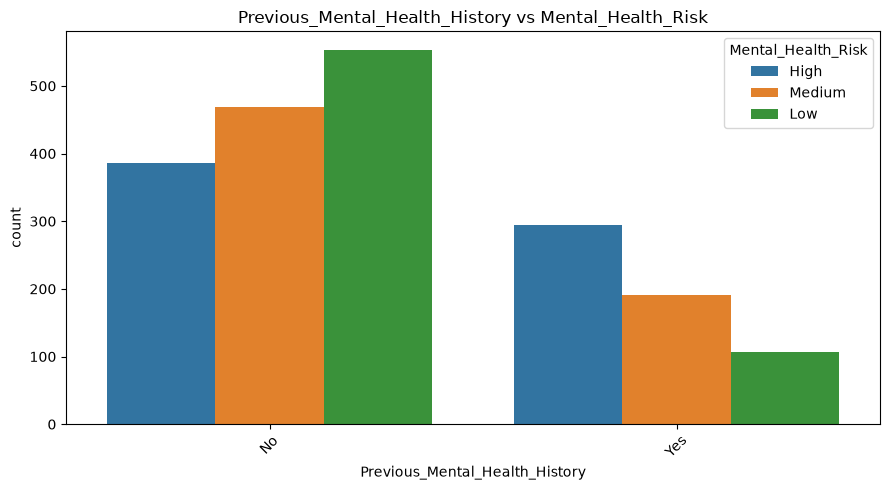

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in categorical_cols:
    plt.figure(figsize=(9, 5))

    sns.countplot(data=df, x=col, hue="Mental_Health_Risk")

    plt.title(f"{col} vs {"Mental_Health_Risk"}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Relations entre variables numériques et cible


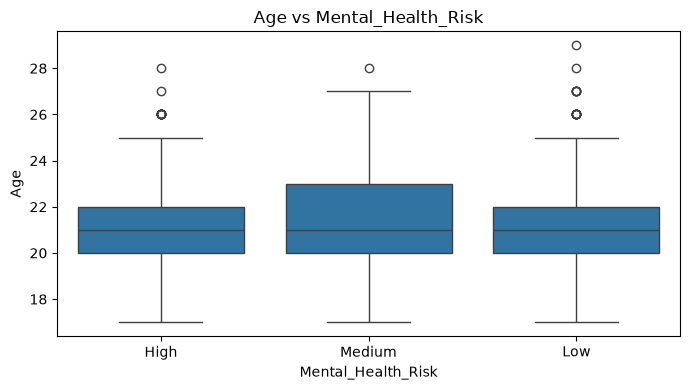

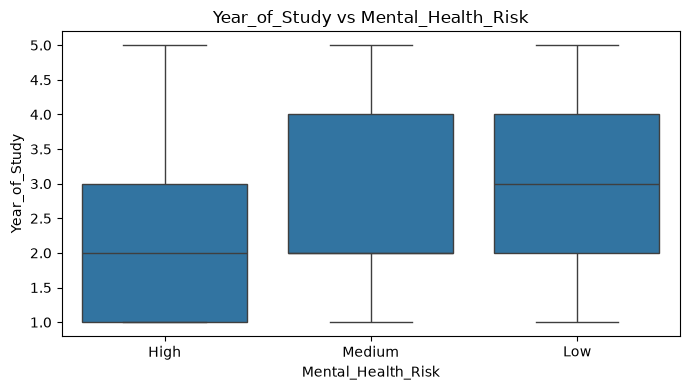

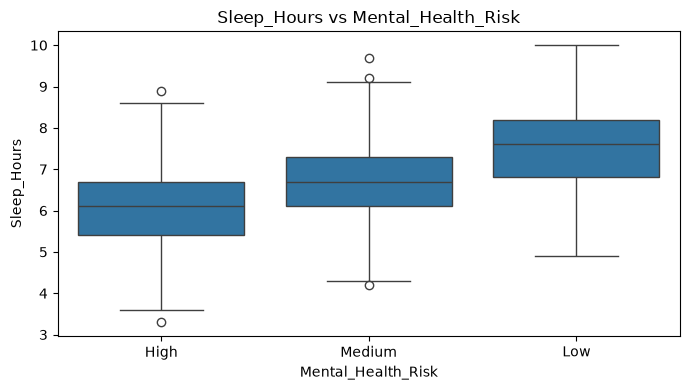

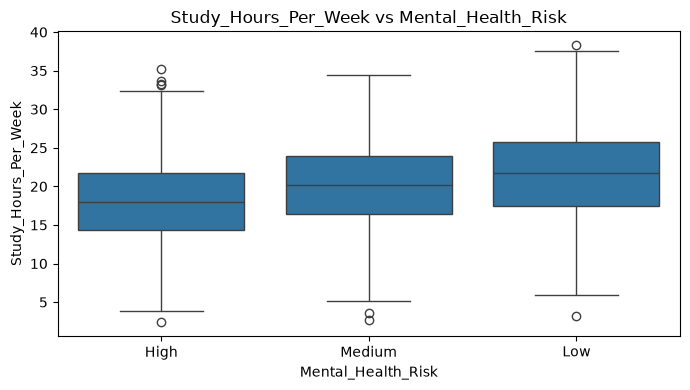

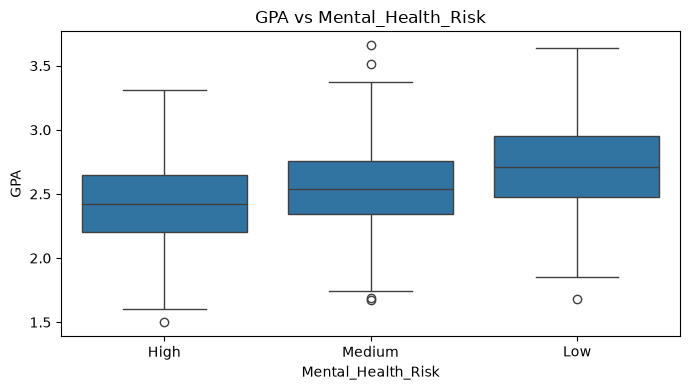

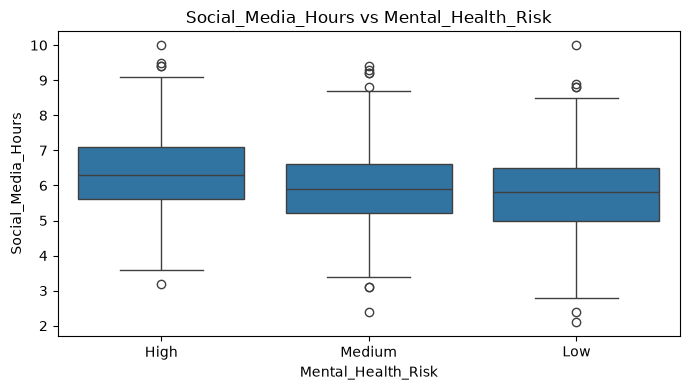

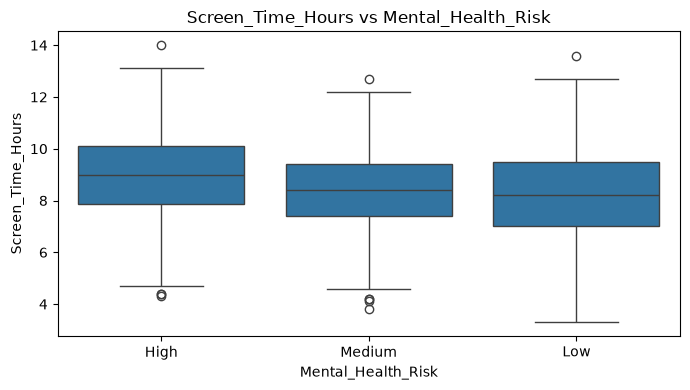

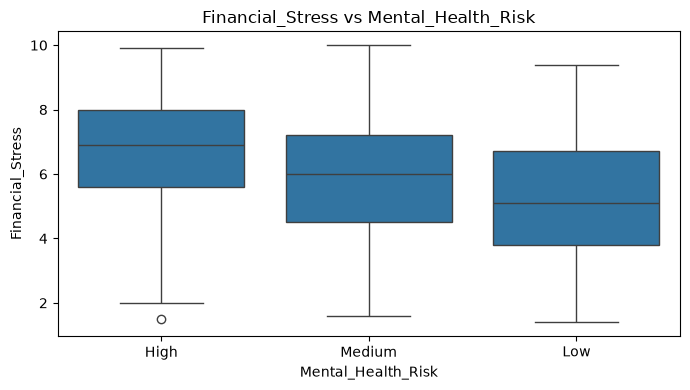

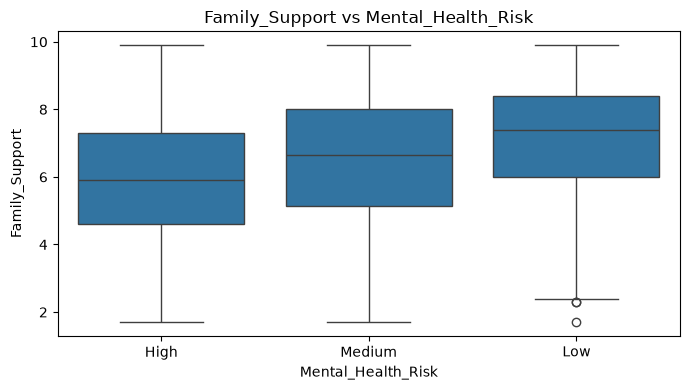

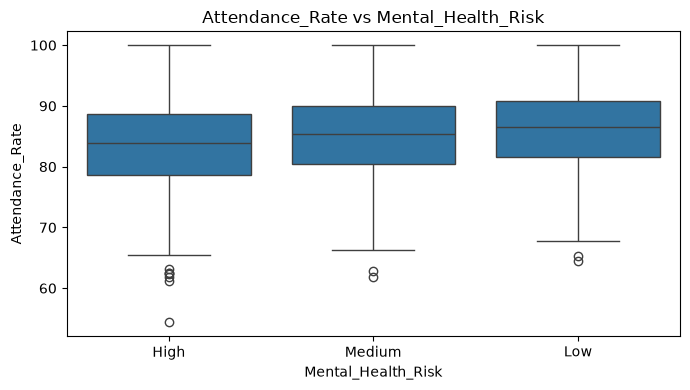

In [16]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x="Mental_Health_Risk", y=col)

    plt.title(f"{col} vs {"Mental_Health_Risk"}")
    plt.tight_layout()
    plt.show()

# Matrice de corrélation

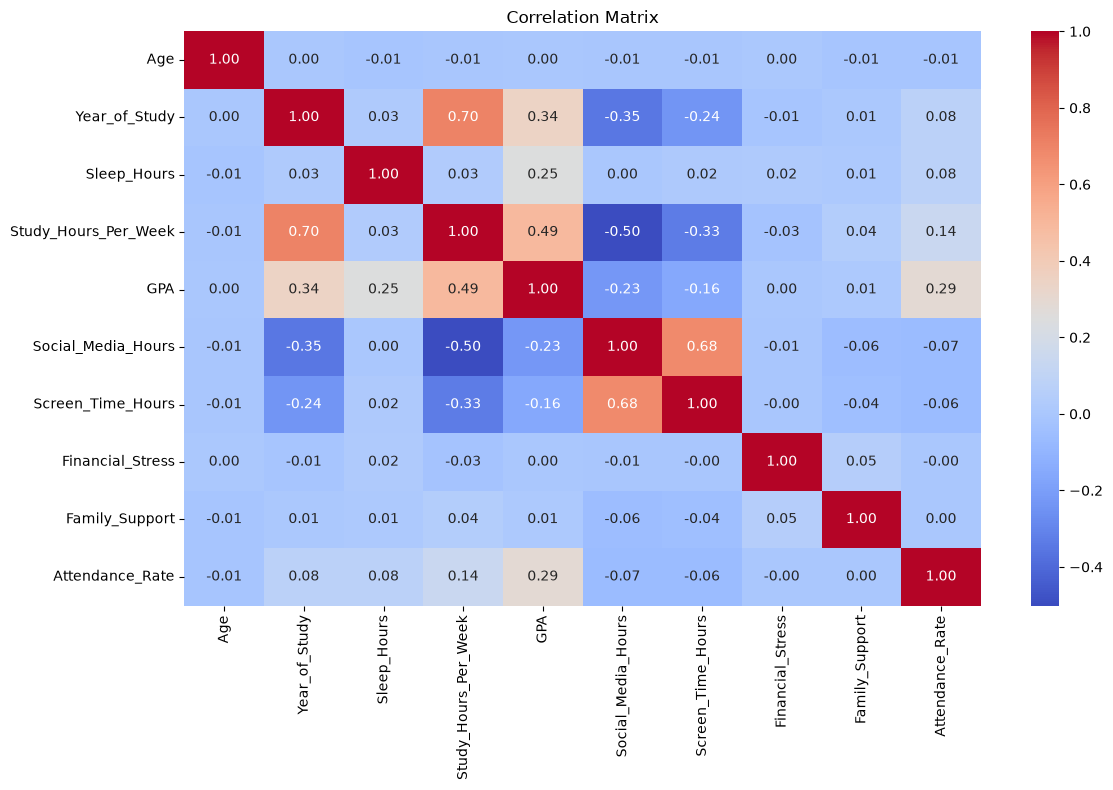

In [17]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
import numpy as np


categories = df.select_dtypes(include="object").columns
ordinal_cat = ["Diet_Quality", "Physical_Activity"]
nominal_cat = categories.drop(["Diet_Quality", "Physical_Activity", "Mental_Health_Risk","Student_ID"])
numerical_cols = (
    df.select_dtypes(include="number")
    .columns
    .drop("Mental_Health_Risk", errors="ignore")
)



Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)


IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = (
    (df[numerical_cols] < lower_bound) |
    (df[numerical_cols] > upper_bound)
)



for col in numerical_cols:
    df[col] = df[col].clip(
        lower=lower_bound[col],
        upper=upper_bound[col]
    )

nominal_categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ('encoder', OneHotEncoder(handle_unknown= "ignore", sparse_output=False))
])
ordinal_categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ('encoder', OrdinalEncoder( categories=[
            ["Poor", "Average", "Good"],
           
            ["Low", "Moderate", "High"]
        ]))
])
numerical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
    
])

preprocessor = ColumnTransformer(
    transformers=[
        ('nom_cat', nominal_categorical_pipe, nominal_cat ),
        ('ord_cat', ordinal_categorical_pipe, ordinal_cat ),
        ('num', numerical_pipe, numerical_cols)
    ],
    remainder="drop"
)
X = df.drop(columns=["Mental_Health_Risk"])
y = (
    df["Mental_Health_Risk"]
    .str.strip()
    .str.lower()
    .map({
        "low": 0,
        "medium": 1,
        "high": 2
    })
    .astype("int64")
)

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size =0.2, random_state=42)

rf_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("randomForest", RandomForestClassifier(random_state=42))
])

rf_grid = {
    "randomForest__n_estimators" : [100,200,300],
    "randomForest__max_depth" : [None,1,2],
    "randomForest__min_samples_leaf" : [10,20]
}

rf_cv = GridSearchCV(
    rf_pipeline,
    rf_grid,
    cv=5,
    scoring="f1_macro"
)
rf_cv.fit(X_train, y_train)
best_model = rf_cv.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Low", "Medium", "High"]
))

print(confusion_matrix(y_test, y_pred))

C:\Users\laaou\AppData\Local\Temp\ipykernel_13004\1932256154.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categories = df.select_dtypes(include="object").columns


Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')
              precision    recall  f1-score   support

         Low       0.69      0.75      0.72       125
      Medium       0.51      0.46      0.49       132
        High       0.75      0.76      0.75       143

    accuracy                           0.66       400
   macro avg       0.65      0.66      0.65       400
weighted avg       0.65      0.66      0.65       400

[[ 94  28   3]
 [ 38  61  33]
 [  5  30 108]]


Mental_Health_Risk
2    680
1    660
0    660
Name: count, dtype: int64
Mental_Health_Risk
2    34.0
1    33.0
0    33.0
Name: proportion, dtype: float64


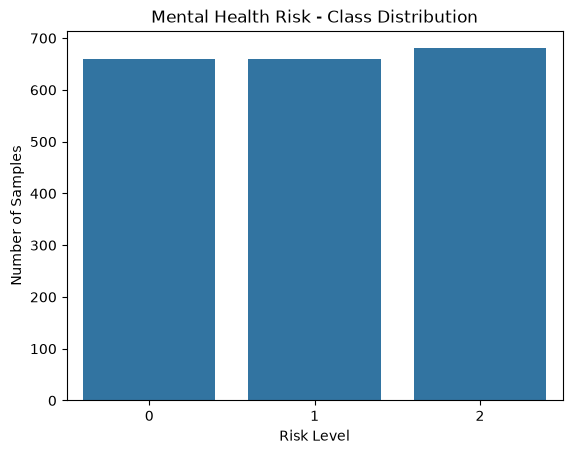

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the samples in each class
print(y.value_counts())

# Calculate percentages
print(y.value_counts(normalize=True) * 100)

# Visualize class distribution
sns.countplot(x=y)

plt.title("Mental Health Risk - Class Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Samples")
plt.show()